<a href="https://colab.research.google.com/github/kristinneibling/hello-world/blob/master/WhaleScaleTest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⬆️ Upload your whale recording (.wav) below


Saving whale_song.wav to whale_song (24).wav

Analyzing: whale_song (24).wav

🎶 Whale tones for 45-key MIDI (low → high):
 1. 38.34 Hz  |  occurrences: 6
 2. 55.97 Hz  |  occurrences: 1
 3. 61.69 Hz  |  occurrences: 3
 4. 65.97 Hz  |  occurrences: 3
 5. 75.50 Hz  |  occurrences: 0
 6. 148.40 Hz  |  occurrences: 4
 7. 155.55 Hz  |  occurrences: 2
 8. 299.44 Hz  |  occurrences: 1
 9. 306.59 Hz  |  occurrences: 2
10. 314.69 Hz  |  occurrences: 4
11. 329.46 Hz  |  occurrences: 1
12. 338.04 Hz  |  occurrences: 4
13. 342.80 Hz  |  occurrences: 3
14. 348.04 Hz  |  occurrences: 2
15. 355.19 Hz  |  occurrences: 0
16. 365.67 Hz  |  occurrences: 1
17. 374.72 Hz  |  occurrences: 2
18. 380.92 Hz  |  occurrences: 4
19. 387.59 Hz  |  occurrences: 3
20. 872.63 Hz  |  occurrences: 1


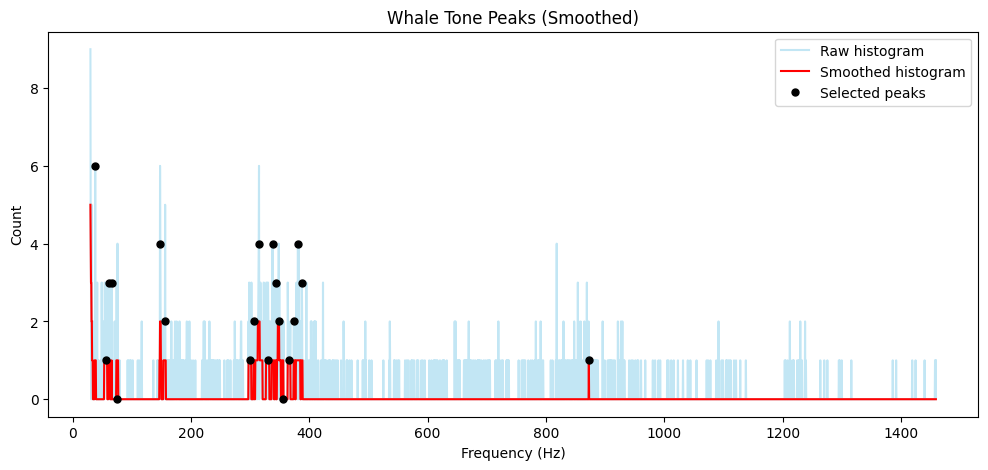


✅ Saved whale tones to 'whale_tones_45keys.txt'


In [28]:
# 🐋 Whale Tone Extractor for 45-Key MIDI Controller

# --- Step 1: Install dependencies ---
!pip install librosa matplotlib scipy --quiet

# --- Step 2: Upload whale audio file ---
from google.colab import files
import librosa, numpy as np, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

print("⬆️ Upload your whale recording (.wav) below")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(f"\nAnalyzing: {filename}")

# --- Step 3: Load audio ---
y, sr = librosa.load(filename, sr=None)

# Optional: trim silence
y, _ = librosa.effects.trim(y, top_db=20)

# --- Step 4: Extract pitches using YIN ---
# Optimal frame length for low-frequency accuracy
frame_length = 4096
fmin, fmax = 30, 1500
pitches = librosa.yin(y, fmin=fmin, fmax=fmax, sr=sr, frame_length=frame_length)
pitches = pitches[~np.isnan(pitches)]
pitches = pitches[(pitches >= fmin) & (pitches <= fmax)]

# --- Step 5: Build histogram ---
num_bins = 3000  # controls resolution
hist, edges = np.histogram(pitches, bins=num_bins)

# --- Step 6: Smooth histogram ---
sigma = 1  # adjust if needed
hist_smooth = gaussian_filter1d(hist, sigma=sigma)

# --- Step 7: Find peaks ---
peak_indices, _ = find_peaks(hist_smooth, prominence=1)
peak_freqs = (edges[peak_indices] + edges[peak_indices + 1]) / 2
peak_counts = hist[peak_indices]

# --- Step 8: Sort by frequency (low -> high) ---
sorted_indices = np.argsort(peak_freqs)
peak_freqs_sorted = peak_freqs[sorted_indices]
peak_counts_sorted = peak_counts[sorted_indices]

# --- Step 9: Keep top 45 peaks ---
top_n = min(45, len(peak_freqs_sorted))
top_freqs_final = peak_freqs_sorted[:top_n]
top_counts_final = peak_counts_sorted[:top_n]

# --- Step 10: Display results ---
print("\n🎶 Whale tones for 45-key MIDI (low → high):")
for i, (f, c) in enumerate(zip(top_freqs_final, top_counts_final), start=1):
    print(f"{i:2d}. {f:.2f} Hz  |  occurrences: {c}")

# --- Step 11: Plot histogram with peaks ---
plt.figure(figsize=(12,5))
plt.plot(edges[:-1], hist, label='Raw histogram', alpha=0.5, color='skyblue')
plt.plot(edges[:-1], hist_smooth, label='Smoothed histogram', color='red')
plt.plot(top_freqs_final, top_counts_final, "k.", markersize=10, label="Selected peaks")
plt.title("Whale Tone Peaks (Smoothed)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.legend()
plt.show()

# --- Step 12: Save peaks to file ---
np.savetxt("whale_tones_45keys.txt", np.column_stack((top_freqs_final, top_counts_final)),
           fmt="%.2f", header="Frequency(Hz)  Count")
print("\n✅ Saved whale tones to 'whale_tones_45keys.txt'")
